# 09 - Support Vector Machine (SVM)

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Model:** Support Vector Machine (SVM)

**Goal:** Train and evaluate the SVM classification model using the processed PhiUSIIL phishing URL dataset, compare different feature sets, and evaluate the URL-only model on an independent external dataset.

**Model Overview:** Support Vector Machine is a supervised machine learning algorithm that identifies a suitable decision boundary to separate legitimate and phishing URLs. Feature scaling helps ensure that features with different numerical ranges are appropriately considered during training.

**Objectives:**
- Train the SVM model to classify legitimate and phishing URLs.
- Identify suitable hyperparameters through hyperparameter tuning.
- Evaluate model performance using cross-validation.
- Compare different feature sets.
- Measure accuracy, precision, recall, F1-score and ROC-AUC.
- Evaluate generalization using an external dataset.
- Save model evaluation results and confusion matrices.

## Setup

We load the libraries and the shared functions from `src/`. Every team member uses the same functions, so all results are calculated in the same way and can be compared fairly.

In [1]:
import sys
import time
from pathlib import Path

import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.svm import LinearSVC

sys.path.append(str(Path("..").resolve()))

from src.data import (
    get_feature_sets,
    load_train_test,
    load_url_experiment,
    sample_rows,
)

from src.evaluation import (
    RANDOM_STATE,
    cross_validate_model,
    evaluate_model,
    make_cv,
    make_scaled_pipeline,
    plot_confusion_matrix,
    save_results,
)

In [2]:
X_train, X_test, y_train, y_test = load_train_test()
feature_sets = get_feature_sets()

print(f"Training set: {X_train.shape[0]:,} rows | {X_train.shape[1]} features")
print(f"Test set:     {X_test.shape[0]:,} rows | {X_test.shape[1]} features")

Training set: 188,296 rows | 69 features
Test set:     47,074 rows | 69 features


## Model Settings

We choose the model, the settings we want to try during tuning, and the sample size for tuning.

In [3]:
MODEL_NAME = "SVM"

model = make_scaled_pipeline(
    LinearSVC(
        max_iter=5000,
        random_state=RANDOM_STATE
    )
)

param_grid = {
    "linearsvc__C": [0.01, 0.1, 1, 10],
}

TUNING_SAMPLE_SIZE = 30000

print("Model:", MODEL_NAME)
print("Tuning sample size:", TUNING_SAMPLE_SIZE)
print("Hyperparameters:", param_grid)

Model: SVM
Tuning sample size: 30000
Hyperparameters: {'linearsvc__C': [0.01, 0.1, 1, 10]}


## 1. Hyperparameter Tuning

We try each combination of settings in `param_grid` using 3-fold cross-validation on the training set, and keep the one with the best F1-score. The test set is not used here.

In [4]:
X_tune, y_tune = sample_rows(
    X_train,
    y_train,
    TUNING_SAMPLE_SIZE
)

search = GridSearchCV(
    model,
    param_grid,
    scoring="f1",
    cv=make_cv(3),
    n_jobs=-1
)

search.fit(X_tune, y_tune)

best_model = search.best_estimator_

print(f"Best settings: {search.best_params_}")
print(f"Best cross-validation F1: {search.best_score_:.4f}")

Best settings: {'linearsvc__C': 0.1}
Best cross-validation F1: 1.0000


## 2. Cross-Validation

We check the best model with 5-fold stratified cross-validation. The mean shows the usual score, and the standard deviation (Std) shows how stable the model is. A small Std means the model gives similar results on different parts of the data.

In [5]:
cv_results = cross_validate_model(best_model, X_tune, y_tune)
cv_results.round(4)

,Mean,Std
Accuracy,0.9999,0.0001
Precision,1.0000,0.0000
Recall,0.9998,0.0002
F1,0.9999,0.0001
ROC-AUC,1.0000,0.0000


## 3. Final Test

We train the best model on the full training set and test it once on the test set. This is the score we report for this model.

In [6]:
start = time.perf_counter()
final_model = clone(best_model).fit(X_train, y_train)
train_time = time.perf_counter() - start

test_results = evaluate_model(final_model, X_test, y_test)
print(f"Training time: {train_time:.1f} seconds")
pd.Series(test_results).round(4).to_frame("Test Score")

Training time: 3.6 seconds


,Test Score
Accuracy,1.0000
Precision,1.0000
Recall,0.9999
F1,1.0000
ROC-AUC,1.0000


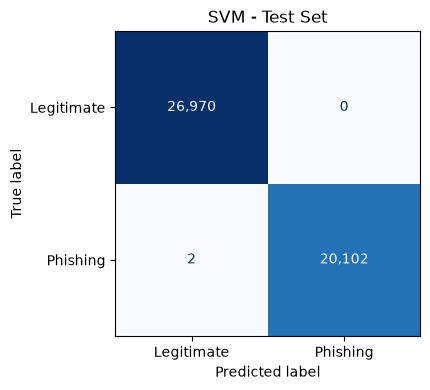

In [7]:
plot_confusion_matrix(y_test, final_model.predict(X_test), f"{MODEL_NAME} - Test Set")

## 4. Feature Set Comparison

We train the same model on two smaller feature sets to answer two questions:

- **Original features only:** do our new features from feature engineering improve the model?
- **Without `URLSimilarityIndex`:** does the model still work well without its strongest feature?

In [8]:
feature_results = {}

for feature_name, columns in feature_sets.items():
    if feature_name == "All features":
        continue

    comparison_model = clone(best_model)
    comparison_model.fit(X_train[columns], y_train)

    feature_results[feature_name] = evaluate_model(
        comparison_model,
        X_test[columns],
        y_test
    )

pd.DataFrame(feature_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
Original features only,0.9999,1.0,0.9999,0.9999,1.0
Without URLSimilarityIndex,0.9999,1.0,0.9998,0.9999,1.0


## 5. Experiment 2: URL Features Only

Here the model only uses the 18 URL features that we can create from any URL. We train it on PhiUSIIL and test it on both the PhiUSIIL test set and the external dataset. The difference between the two scores shows how well the model works on data from a different source.

In [9]:
X_url_train, X_url_test, X_external, y_url_train, y_url_test, y_external = load_url_experiment()

url_model = clone(best_model).fit(X_url_train, y_url_train)
url_results = {
    "PhiUSIIL test set": evaluate_model(url_model, X_url_test, y_url_test),
    "External dataset": evaluate_model(url_model, X_external, y_external),
}
pd.DataFrame(url_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
PhiUSIIL test set,0.9945,1.0000,0.9871,0.9935,0.9977
External dataset,0.5020,0.5026,0.9921,0.6672,0.6608


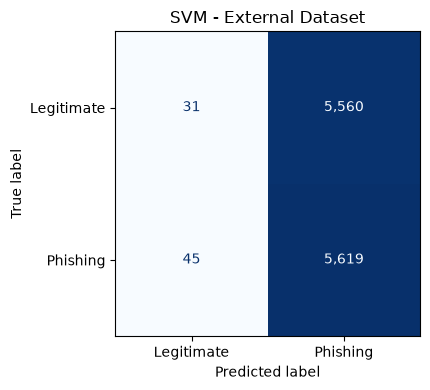

In [10]:
plot_confusion_matrix(y_external, url_model.predict(X_external), f"{MODEL_NAME} - External Dataset")

## 6. Save the Results

We save all results in one table. The comparison notebook will later load the tables of all models.

In [11]:
results = [
    {"Experiment": "Cross-validation", **cv_results["Mean"].to_dict()},
    {"Experiment": "Test set - All features", **test_results, "Train Time (s)": train_time},
    {"Experiment": "Test set - Original features only", **feature_results["Original features only"]},
    {"Experiment": "Test set - Without URLSimilarityIndex", **feature_results["Without URLSimilarityIndex"]},
    {"Experiment": "URL features - PhiUSIIL test set", **url_results["PhiUSIIL test set"]},
    {"Experiment": "URL features - External dataset", **url_results["External dataset"]},
]

save_results(MODEL_NAME, results).round(4)

,Model,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s)
0,SVM,Cross-validation,0.9999,1.0000,0.9998,0.9999,1.0000,NaN
1,SVM,Test set - All features,1.0000,1.0000,0.9999,1.0000,1.0000,3.5873
2,SVM,Test set - Original features only,0.9999,1.0000,0.9999,0.9999,1.0000,NaN
3,SVM,Test set - Without URLSimilarityIndex,0.9999,1.0000,0.9998,0.9999,1.0000,NaN
4,SVM,URL features - PhiUSIIL test set,0.9945,1.0000,0.9871,0.9935,0.9977,NaN
5,SVM,URL features - External dataset,0.5020,0.5026,0.9921,0.6672,0.6608,NaN


## 7. Findings

### Model Performance and Stability

The Support Vector Machine (SVM) model was implemented using `LinearSVC` with log transformation and standard feature scaling. Hyperparameter tuning was performed using a stratified sample of 30,000 training instances and three-fold cross-validation.

The best regularization parameter was identified as `C = 0.1`, with a reported tuning F1-score of 1.0000 at four-decimal precision.

The final model achieved an internal test accuracy of **99.9958%**, precision of **100%**, recall of **99.9901%**, F1-score of **99.9950%**, and ROC-AUC of **99.9998%**.

The five-fold cross-validation produced a mean accuracy of 99.9933% and a mean F1-score of 99.9922%. The low standard deviation values indicate consistent performance across the validation folds. However, the cross-validation used the same training sample involved in hyperparameter selection.

The final model was trained on the full training dataset of 188,296 samples, with a recorded fitting time of approximately 3.59 seconds.

The internal confusion matrix showed that 47,072 out of 47,074 URLs were correctly classified. Only two phishing URLs were incorrectly classified as legitimate, while no legitimate URLs were incorrectly classified as phishing.

### Feature Set Comparison

The model achieved an accuracy of 99.9958% using all features and 99.9936% using only the original features. This indicates that the additional engineered features provided a marginal improvement in internal classification performance.

Removing `URLSimilarityIndex` reduced the accuracy slightly to 99.9915%. However, the model maintained a high level of internal classification performance without this feature.

The differences between these feature sets were relatively small, suggesting that the model performed well across all three tested feature configurations.

### External Dataset Evaluation

Using only the 18 URL-based features, the SVM model achieved an accuracy of 99.45%, an F1-score of 99.35%, and a ROC-AUC of 99.77% on the PhiUSIIL test dataset.

However, when evaluated on the independent external dataset, accuracy decreased to 50.20%, the F1-score decreased to 66.72%, and ROC-AUC decreased to 66.08%.

The accuracy decreased by approximately 49.25 percentage points, indicating poor generalization to URLs from a different data source.

The external confusion matrix showed that 5,560 legitimate URLs were incorrectly classified as phishing, while only 31 legitimate URLs were correctly identified. The model predicted 11,179 out of 11,255 external samples as phishing.

Although the external recall remained high at 99.21%, the low precision and large number of false positives indicate that the model struggled to distinguish legitimate URLs from phishing URLs at its default decision threshold.

### Reasons for Reduced External Performance

The reduced external performance may be associated with dataset distribution shift, differences in URL characteristics, or inconsistencies in feature extraction and label definitions between the datasets.

Although the model achieved strong performance on the PhiUSIIL dataset, these results do not guarantee reliable classification on URLs obtained from different sources.

The external ROC-AUC of 0.6608 indicates some ability to distinguish between the two classes through the model's decision scores. However, further investigation of feature distributions, label consistency, potential data leakage, and decision-threshold selection using an appropriate validation dataset is necessary.

### Conclusion

The SVM model demonstrated excellent internal classification performance, consistent cross-validation results, and a low number of classification errors on the PhiUSIIL dataset.

The feature set comparison showed that the additional engineered features provided a marginal improvement in internal performance. Nevertheless, the URL-only model demonstrated poor external classification performance and a high false-positive rate.

Therefore, although SVM is an effective classifier for the internal dataset, further investigation and improvement are required before it can be considered reliable for real-world phishing URL detection.